# Planetary eddies: background flow
Figure 11. Settings: `background.json`. Build fresh monthly fields once with `python background.py --build`; this notebook validates and loads them. The 31/61/91-day comparison uses identical eddy-days and is an internal check.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
from IPython.display import Markdown, display

HERE = Path.cwd().resolve()
if (HERE / "background" / "background.py").is_file():
    HERE = HERE / "background"
elif not (HERE / "background.py").is_file():
    HERE = HERE / "seacofs_eddy_tilt_analysis" / "manuscript" / "background"
sys.path.insert(0, str(HERE))
import background
CONFIG = HERE / "background.json"

In [2]:
results = background.run(CONFIG)
import matplotlib.pyplot as plt
plt.close("all")

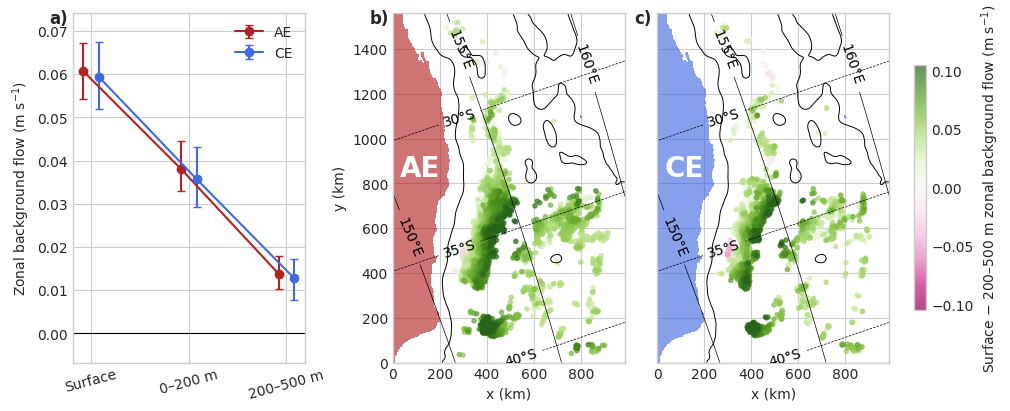

In [3]:
display(results["figure"])

In [4]:
display(Markdown((results["output_dir"] / "report.md").read_text()))
display(results["window_comparison"])

# Planetary eddies: background flow

Figure 11. Fresh archive build: 9,189 continuous daily fields (1994-01-02–2019-02-28); monthly climatological means use all archive days, including days without eddies. Primary: centred 91-day seasonal climatology, weighted by calendar-month overlap. This is not an event-year running mean; 31/61-day checks use the same monthly fields.

Population: unsmoothed factor-2 planetary dominance; footprint-mean h≥3000 m; saved tilt≥5 km and shared directional QC. Centre-column water depth is checked separately for full 500 m coverage. All three windows and all displayed layers use identical eddy-days.

Velocities are geographic east/north at the source eddy centre grid cell. Layer means use the original static physical sigma-centre depths and midpoint-interface thickness approximation, bounded by surface and bathymetry. Surface denotes the top model level. Require finite full-layer coverage; do not renormalise partially missing depths. 200–500 m mean = (500 U(0–500) − 200 U(0–200))/300. The primary contrast is surface minus 200–500 m zonal velocity, in m/s, not a vertical derivative.

Pooled eddy-day medians; pointwise 95% CIs resample whole eddy tracks (5000 draws, seed 42 with recorded statistic offsets). The median of a daily contrast differs from the contrast between layer medians.

Surface-minus-deep zonal contrast (median [95% CI], m/s):

- 31-day AE: 0.0483 [0.0454, 0.0514]; 4,449 days / 510 eddies; positive fraction 0.967.
- 31-day CE: 0.0489 [0.0458, 0.0520]; 1,874 days / 397 eddies; positive fraction 0.939.
- 61-day AE: 0.0477 [0.0453, 0.0505]; 4,449 days / 510 eddies; positive fraction 0.975.
- 61-day CE: 0.0487 [0.0459, 0.0514]; 1,874 days / 397 eddies; positive fraction 0.948.
- 91-day AE: 0.0473 [0.0449, 0.0500]; 4,449 days / 510 eddies; positive fraction 0.980.
- 91-day CE: 0.0485 [0.0456, 0.0511]; 1,874 days / 397 eddies; positive fraction 0.955.

Internal window checks: window_comparison.csv and window_paired_differences.csv. Do not select a window for stronger results. These are background-flow descriptions, not independent observations of shallow/deep eddy propagation or evidence of causation.

Original three-panel style retained. Map colours saturate at the shared 98th absolute percentile (±0.1044 m/s); all mapped days remain included. The 3000 m contour shows local bathymetry, while population selection uses footprint-mean h.

Tables: flow_summary.csv (layer medians/CIs), window_comparison.csv (daily contrast and support), window_paired_differences.csv, exclusions.csv and sample_audit.csv. members.parquet retains all matched window values; manifest.json records config/code hashes and the independent scratch-product provenance. Outputs are descriptive.

Monthly coverage: monthly_coverage.csv reports original daily support for every layer/component/month at the targeted cells before window exclusions. All target cells have every archive day for every required layer/component.

Selection/exclusions:

- AE, outside deep-planetary directional population: 62,799 days / 1,497 eddies.
- AE, selected: 4,449 days / 510 eddies.
- CE, outside deep-planetary directional population: 63,916 days / 1,600 eddies.
- CE, selected: 1,874 days / 397 eddies.

Window sensitivity (population medians; paired daily differences remain in the internal table):

- AE: median contrast range 0.0473–0.0483 m/s; all three lower 95% CI bounds above zero: True.
- CE: median contrast range 0.0485–0.0489 m/s; all three lower 95% CI bounds above zero: True.


,window_days,Cyc,eddy_days,eddies,median,ci_low,ci_high,q25,q75,positive_fraction,bootstrap_seed
0,31,AE,4449,510,0.048295,0.045373,0.051407,0.029561,0.069252,0.967184,1042
1,31,CE,1874,397,0.048882,0.045796,0.051999,0.028517,0.069391,0.938634,1043
2,61,AE,4449,510,0.047721,0.045276,0.050458,0.031541,0.068437,0.975275,1042
3,61,CE,1874,397,0.048696,0.045908,0.051356,0.030437,0.068066,0.948239,1043
4,91,AE,4449,510,0.047328,0.044898,0.049966,0.032920,0.067455,0.980220,1042
5,91,CE,1874,397,0.048472,0.045591,0.051109,0.030940,0.068829,0.955176,1043
